tokenizacja BPE

Limit: 100 (Faktyczny: 100)
Podział niewidzianych (golfem): ['golf', 'e', 'm']
Podział niewidzianych (turnieju): ['t', 'ur', 'nie', 'j', 'u']

Limit: 200 (Faktyczny: 200)
Podział niewidzianych (golfem): ['golf', 'e', 'm']
Podział niewidzianych (turnieju): ['tur', 'niej', 'u']

Limit: 500 (Faktyczny: 385)
Podział niewidzianych (golfem): ['golf', 'e', 'm']
Podział niewidzianych (turnieju): ['turniej', 'u']

Tabela BPE:
 Limit vocab_size  Faktyczny rozmiar  Śr. tok. (widziane)  UNK (widziane)  Śr. tok. (niewidziane)  UNK (niewidziane)
              100                100             3.000000               0                4.333333                  0
              200                200             1.833333               0                3.333333                  0
              500                385             1.000000               0                2.500000                  0

word2vec
Sąsiedzi 'golf' w Wariancie 1 (dominacja kontekstu sportowego):
[('ciało', 0.898), (

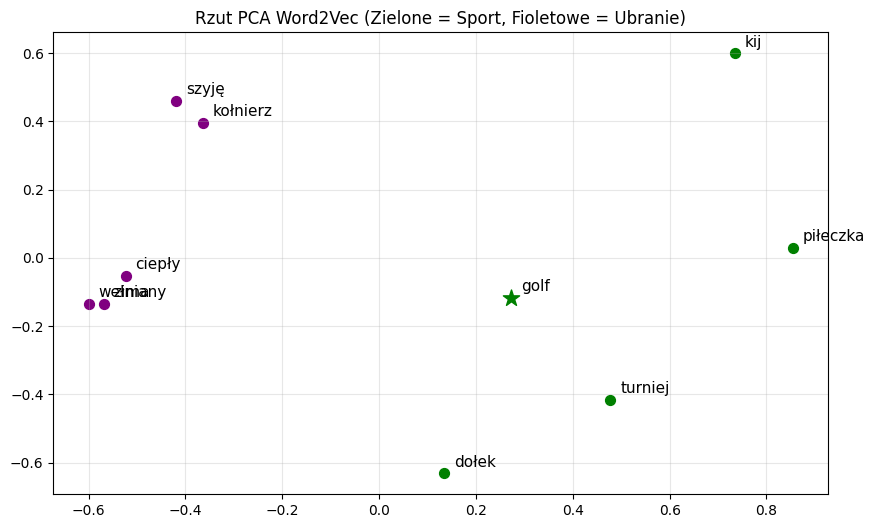

Średnie podobieństwo cosinusowe wewnątrz grupy 'sport': 0.782
Średnie podobieństwo cosinusowe wewnątrz grupy 'ubranie': 0.919
Średnie podobieństwo cosinusowe między grupami: 0.749


In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tokenizers import Tokenizer, models, trainers, pre_tokenizers
from gensim.models import Word2Vec
from sklearn.decomposition import PCA
from sklearn.metrics.pairwise import cosine_similarity

np.random.seed(0)
zdania_sport = [
    "Zamożny biznesmen chętnie gra w golf w każdy weekend.",
    "Jego ulubiony sport to golf, potrzebny jest kij i mała piłeczka.",
    "Na zielonej trawie rozegrano profesjonalny turniej w golf.",
    "Mały dołek był blisko, więc łatwo zakończył ten golf.",
    "Turniej był trudny, a piłeczka nie chciała wpaść grając w golf."
] * 4

zdania_ubranie = [
    "Na zimne dni najlepiej założyć ciepły golf pod grubą kurtkę.",
    "Kiedy nadchodzi zima, ten wełniany golf skutecznie ogrzewa ciało.",
    "Wysoki kołnierz na szyję to główna cecha, jaką ma ten golf.",
    "Kupiłem ciepły golf, który pasuje do moich nowych spodni.",
    "Ten wełniany golf jest idealny, gdy na dworze panuje mroźna zima."
] * 4

zdania_bez_badanego_wyrazu = [
    "Klawiatura mechaniczna jest głośna, ale bardzo wygodna.",
    "Kot śpi na rozgrzanym kaloryferze przez cały mroźny dzień.",
    "Monitor wyświetla bardzo ostry i szczegółowy obraz.",
    "Pies głośno szczeka na listonosza wcześnie rano.",
    "Procesor komputera osiąga wysoką temperaturę podczas obciążenia."
] * 4

korpus_pelny = zdania_sport + zdania_ubranie + zdania_bez_badanego_wyrazu

#6 par form fleksyjnych do oceny BPE (formy widziane w korpusie vs niewidziane)
pary_bpe = [
    ("golf", "golfem"),
    ("kij", "kijami"),
    ("zima", "zimy"),
    ("ciepły", "ciepłym"),
    ("turniej", "turnieju"),
    ("kołnierz", "kołnierzu")
]
formy_widziane = [p[0] for p in pary_bpe]
formy_niewidziane = [p[1] for p in pary_bpe]


print("tokenizacja BPE")
limits = [100, 200, 500]
wyniki_bpe = []

for limit in limits:
    tok = Tokenizer(models.BPE(unk_token='[UNK]'))
    tok.pre_tokenizer = pre_tokenizers.Whitespace()
    trainer = trainers.BpeTrainer(vocab_size=limit, special_tokens=['[UNK]'], min_frequency=1)
    tok.train_from_iterator(korpus_pelny, trainer)

    actual_size = tok.get_vocab_size()

    def evaluate_forms(forms):
        tokens_counts = [len(tok.encode(w).tokens) for w in forms]
        unks = sum(1 for w in forms if '[UNK]' in tok.encode(w).tokens)
        avg_tokens = np.mean(tokens_counts)
        return avg_tokens, unks

    avg_seen, unk_seen = evaluate_forms(formy_widziane)
    avg_unseen, unk_unseen = evaluate_forms(formy_niewidziane)

    wyniki_bpe.append({
        "Limit vocab_size": limit,
        "Faktyczny rozmiar": actual_size,
        "Śr. tok. (widziane)": avg_seen,
        "UNK (widziane)": unk_seen,
        "Śr. tok. (niewidziane)": avg_unseen,
        "UNK (niewidziane)": unk_unseen
    })

    print(f"\nLimit: {limit} (Faktyczny: {actual_size})")
    print(f"Podział niewidzianych (golfem): {tok.encode('golfem').tokens}")
    print(f"Podział niewidzianych (turnieju): {tok.encode('turnieju').tokens}")

df_bpe = pd.DataFrame(wyniki_bpe)
print("\nTabela BPE:")
print(df_bpe.to_string(index=False))

print("\nword2vec")
#12 zdań ze znaczeniem "sport", 4 ze znaczeniem "ubranie"
wariant_1 = zdania_bez_badanego_wyrazu + zdania_sport[:12] + zdania_ubranie[:4]
#4 zdania ze znaczeniem "sport", 12 ze znaczeniem "ubranie"
wariant_2 = zdania_bez_badanego_wyrazu + zdania_sport[:4] + zdania_ubranie[:12]

def prep_corpus(corpus):
    return [[w.lower() for w in s.replace('.', '').replace(',', '').split()] for s in corpus]

z_w1 = prep_corpus(wariant_1)
z_w2 = prep_corpus(wariant_2)

w2v_1 = Word2Vec(z_w1, vector_size=50, window=3, min_count=1, sg=1, epochs=200, seed=0, workers=1)
w2v_2 = Word2Vec(z_w2, vector_size=50, window=3, min_count=1, sg=1, epochs=200, seed=0, workers=1)

print("Sąsiedzi 'golf' w Wariancie 1 (dominacja kontekstu sportowego):")
print([(s, round(v,3)) for s,v in w2v_1.wv.most_similar('golf', topn=5)])

print("\nSąsiedzi 'golf' w Wariancie 2 (dominacja kontekstu odzieżowego):")
print([(s, round(v,3)) for s,v in w2v_2.wv.most_similar('golf', topn=5)])


print("\npca")
grupa_sport = ['golf', 'kij', 'piłeczka', 'turniej', 'dołek']
grupa_ubranie = ['ciepły', 'wełniany', 'zima', 'szyję', 'kołnierz']

slowa = [w for w in grupa_sport + grupa_ubranie if w in w2v_1.wv]
V = np.stack([w2v_1.wv[w] for w in slowa])

pca = PCA(n_components=2, random_state=0)
XY = pca.fit_transform(V)

plt.figure(figsize=(10,6))
colors = ['green' if w in grupa_sport else 'purple' for w in slowa]

for i, w in enumerate(slowa):
    size = 150 if w == 'golf' else 50
    marker = '*' if w == 'golf' else 'o'
    plt.scatter(XY[i,0], XY[i,1], color=colors[i], s=size, marker=marker)
    plt.annotate(w, (XY[i,0]+0.02, XY[i,1]+0.02), fontsize=11)

plt.title("Rzut PCA Word2Vec (Zielone = Sport, Fioletowe = Ubranie)")
plt.grid(alpha=0.3)
plt.show()

#obliczenia cosinusa
vecs_sport = np.stack([w2v_1.wv[w] for w in grupa_sport if w in w2v_1.wv])
vecs_ubranie = np.stack([w2v_1.wv[w] for w in grupa_ubranie if w in w2v_1.wv])

cos_sport = cosine_similarity(vecs_sport)
n_s = len(vecs_sport)
avg_in_sport = (np.sum(cos_sport) - n_s) / (n_s**2 - n_s)

cos_ubranie = cosine_similarity(vecs_ubranie)
n_u = len(vecs_ubranie)
avg_in_ubranie = (np.sum(cos_ubranie) - n_u) / (n_u**2 - n_u)

cos_between = cosine_similarity(vecs_sport, vecs_ubranie)
avg_between = np.mean(cos_between)

print(f"Średnie podobieństwo cosinusowe wewnątrz grupy 'sport': {avg_in_sport:.3f}")
print(f"Średnie podobieństwo cosinusowe wewnątrz grupy 'ubranie': {avg_in_ubranie:.3f}")
print(f"Średnie podobieństwo cosinusowe między grupami: {avg_between:.3f}")